Reading power logs from: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/power_logs/gpt2
Saving plots to: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/plots/gpt2
tp1_pp1_dp4: avg=553.5W  steady_avg=647.0W  peak=706.7W  samples=505
tp4_pp1_dp1: avg=453.1W  steady_avg=481.6W  peak=502.4W  samples=1215
tp1_pp4_dp1: avg=462.9W  steady_avg=505.6W  peak=540.6W  samples=834
tp2_pp2_dp1: avg=445.6W  steady_avg=476.5W  peak=500.2W  samples=1075
tp2_pp1_dp2: avg=505.4W  steady_avg=568.1W  peak=599.7W  samples=712
tp1_pp2_dp2: avg=492.5W  steady_avg=555.7W  peak=583.0W  samples=690
hybrid_schedule [SCHEDULE]: avg=445.1W  steady_avg=477.6W  peak=582.3W  samples=899


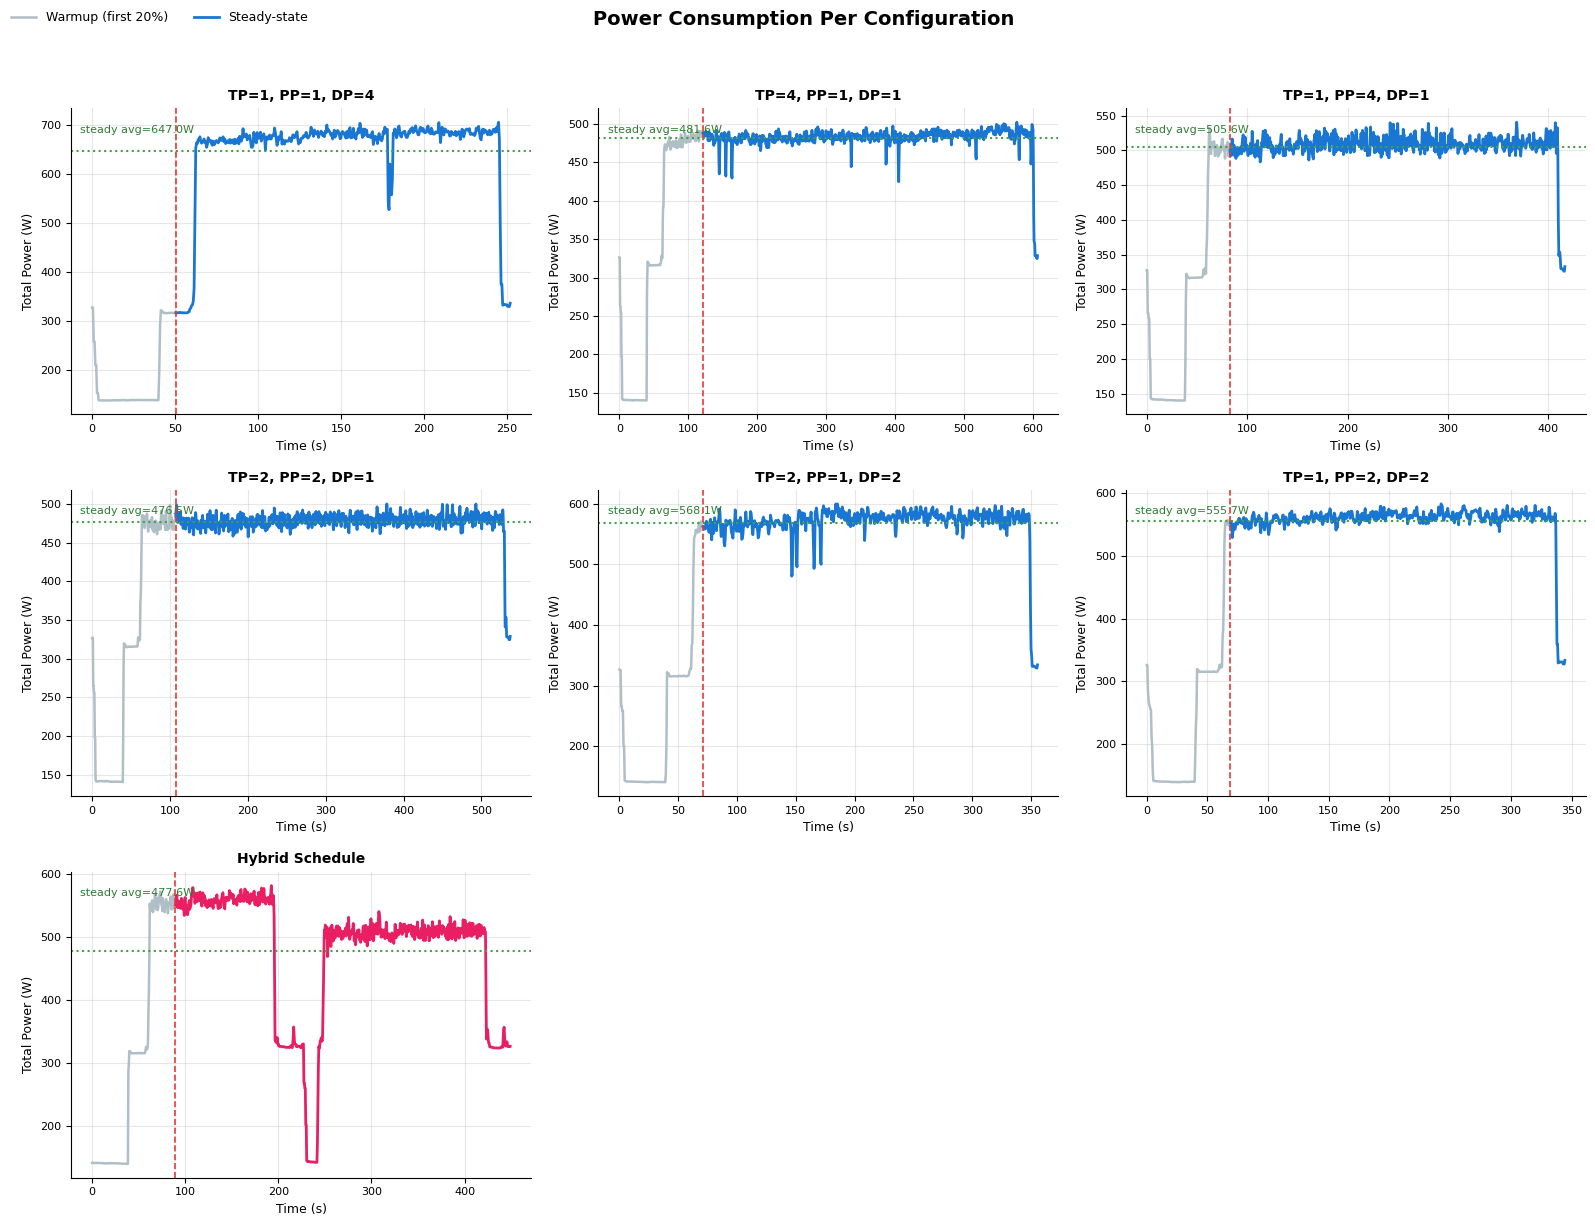

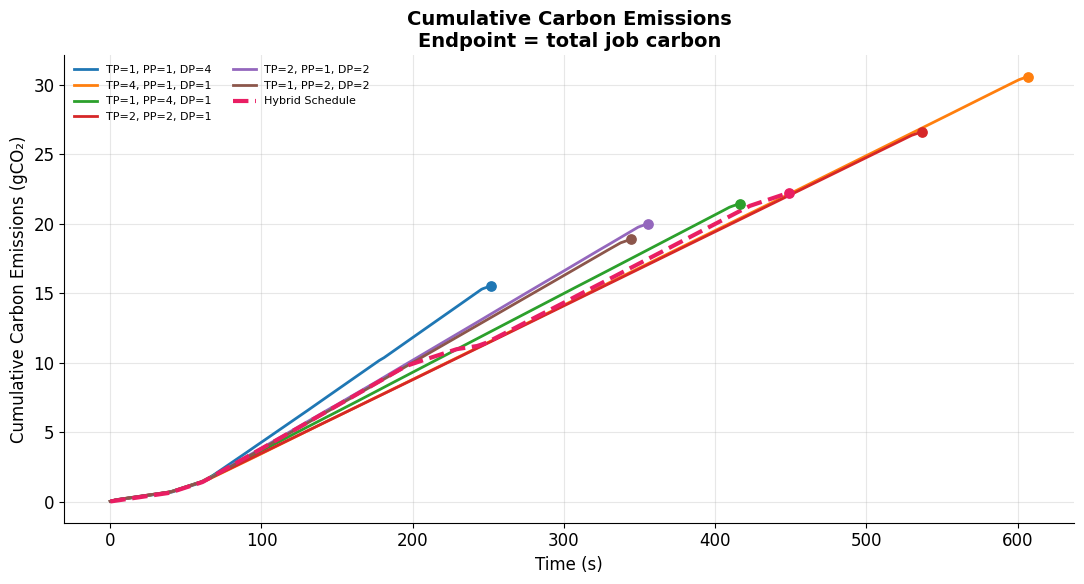


CARBON SCHEDULE: A = [200, 600] gCO₂/kWh
Fixed baseline:  400 gCO₂/kWh

Config                    |   Fixed CI | Varying CI |        Δ
------------------------------------------------------------
TP=1,PP=1,DP=4            |    15.53 g |    17.11 g |  +10.2%
TP=4,PP=1,DP=1            |    30.58 g |    31.57 g |   +3.2%
TP=1,PP=4,DP=1            |    21.45 g |    22.42 g |   +4.5%
TP=2,PP=2,DP=1            |    26.61 g |    27.54 g |   +3.5%
TP=2,PP=1,DP=2            |    19.99 g |    21.27 g |   +6.4%
TP=1,PP=2,DP=2            |    18.88 g |    20.07 g |   +6.3%
Hybrid Schedule           |    22.23 g |    22.55 g |   +1.4%


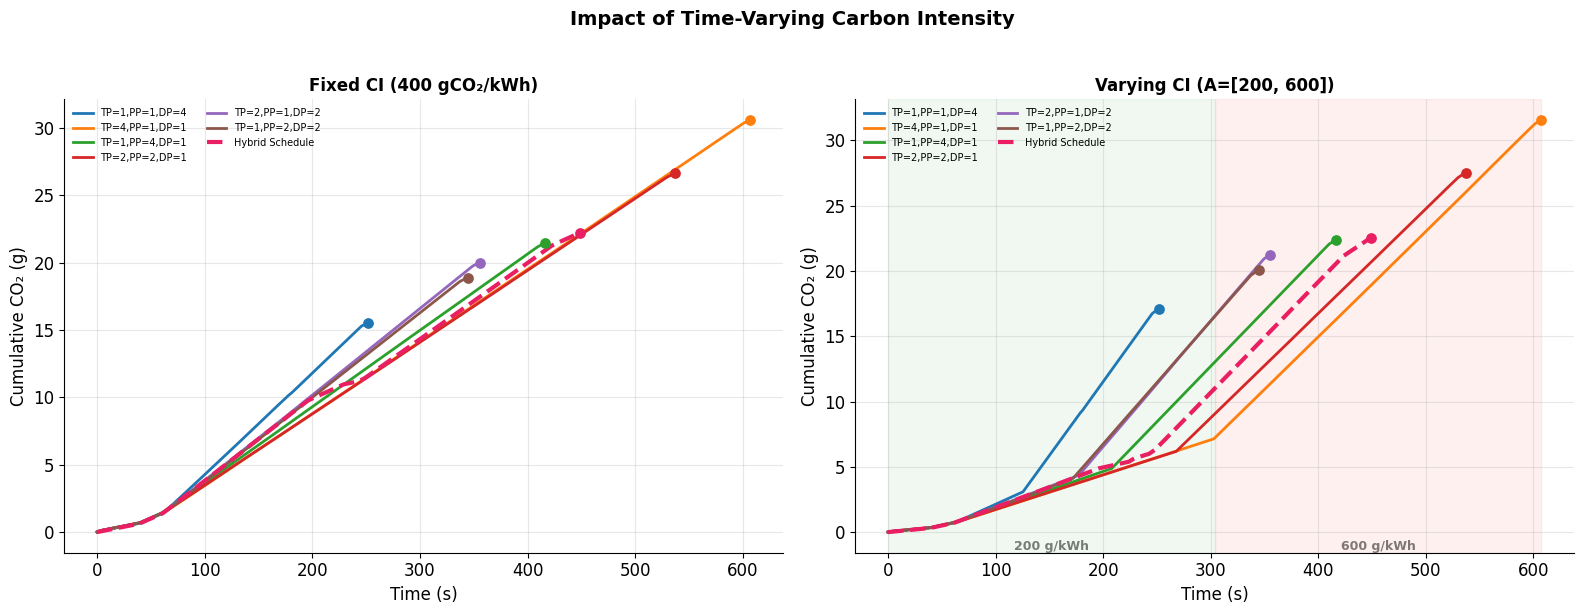

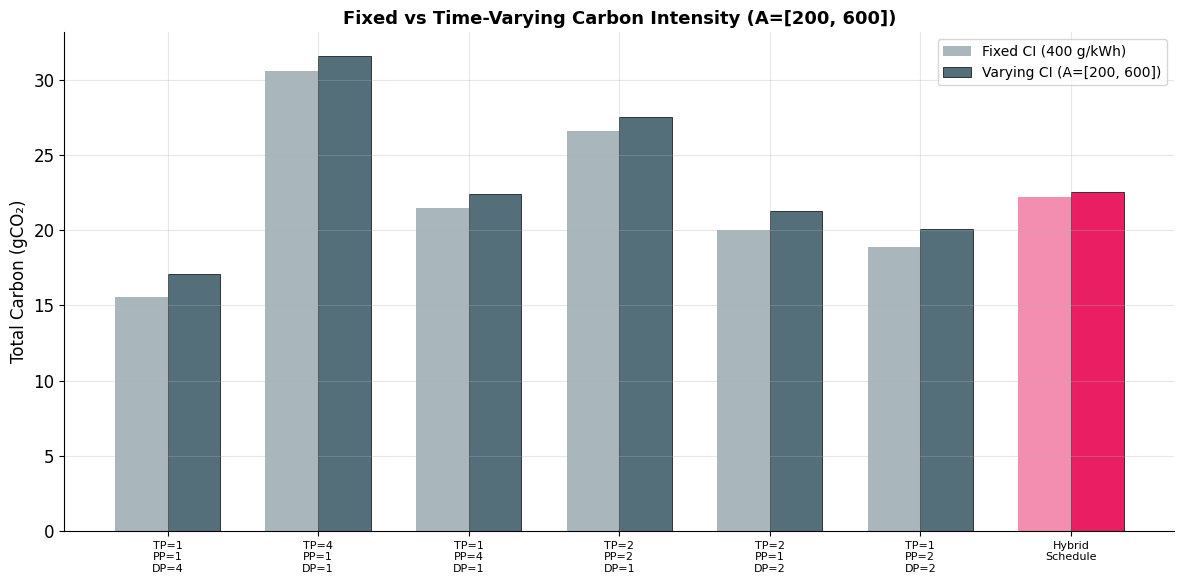


Optimal carbon-aware schedule for A=[200, 600]:
  Period 1 (CI=200) → tp1_pp1_dp4 (fast, power ok since CI is low)
  Period 2 (CI=600) → tp2_pp2_dp1 (low power since CI is high)

Label                     |    Time |   Power |   Energy |   Carbon |       Tput
--------------------------------------------------------------------------------
DP=4 (TP=1,PP=1)          |  252.5s |  553.5W |   38.82Wh |  15.53gCO₂ |  12977.4 tok/s
TP=4 (PP=1,DP=1)          |  607.5s |  453.1W |   76.46Wh |  30.58gCO₂ |   5393.9 tok/s
PP=4 (TP=1,DP=1)          |  417.0s |  462.9W |   53.62Wh |  21.45gCO₂ |   7858.0 tok/s
TP=2,PP=2 (DP=1)          |  537.5s |  445.6W |   66.54Wh |  26.61gCO₂ |   6096.4 tok/s
TP=2,DP=2 (PP=1)          |  356.0s |  505.4W |   49.98Wh |  19.99gCO₂ |   9204.5 tok/s
PP=2,DP=2 (TP=1)          |  345.0s |  492.5W |   47.20Wh |  18.88gCO₂ |   9498.0 tok/s
Hybrid Schedule           |  449.5s |  445.1W |   55.58Wh |  22.23gCO₂ |   7289.9 tok/s ★


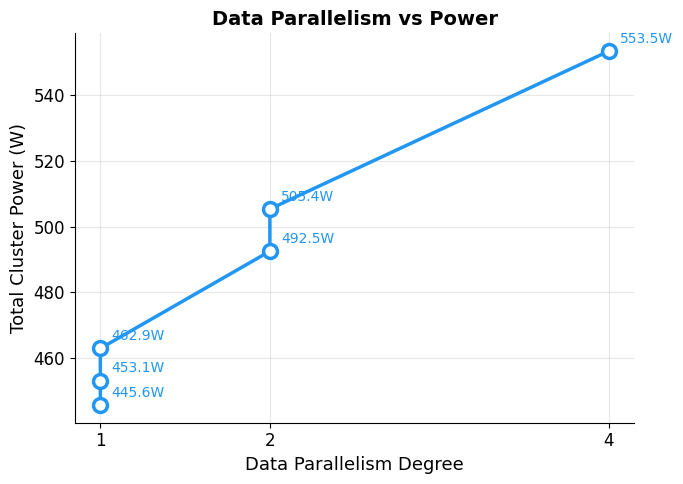

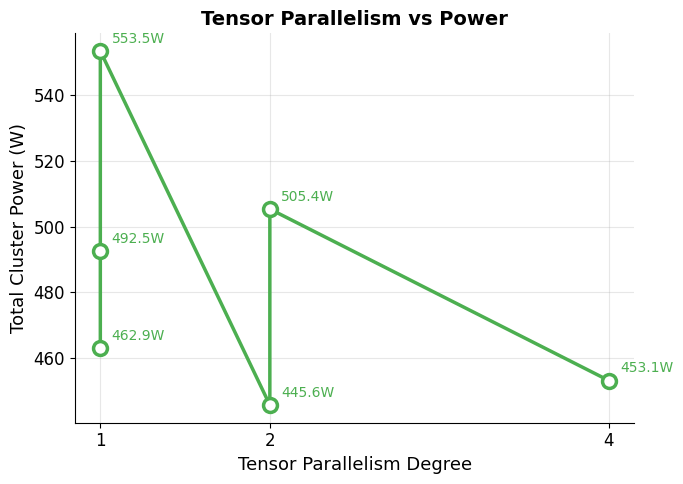

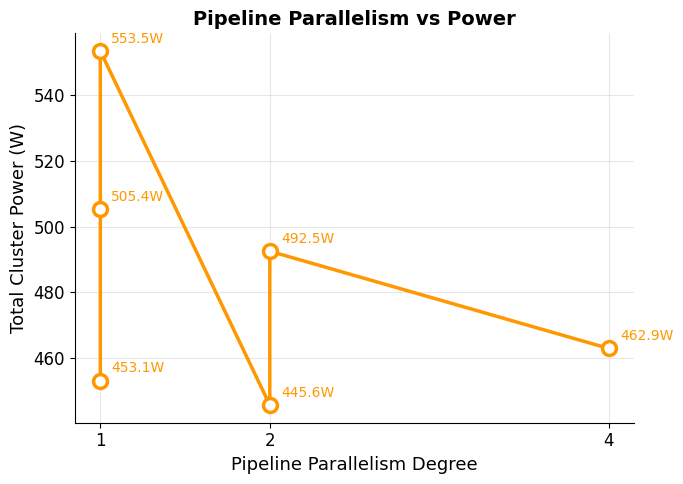

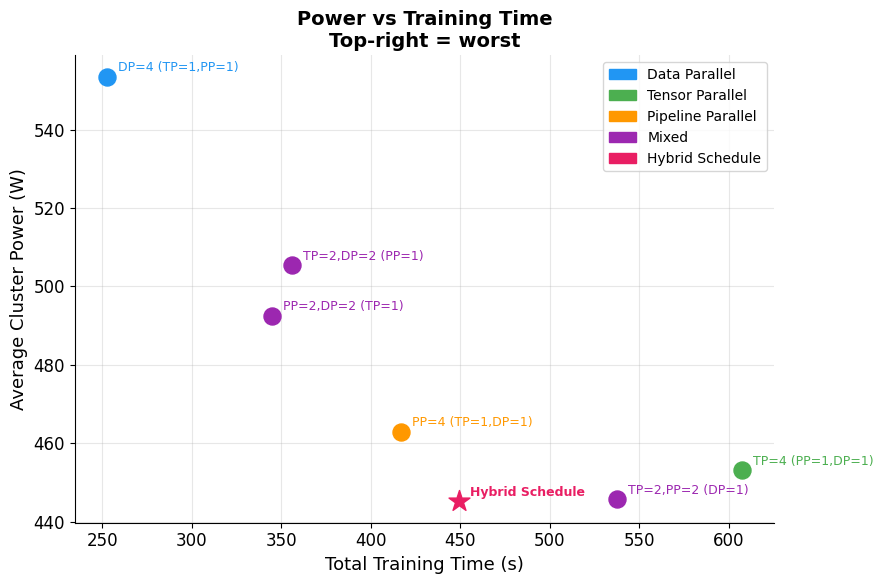

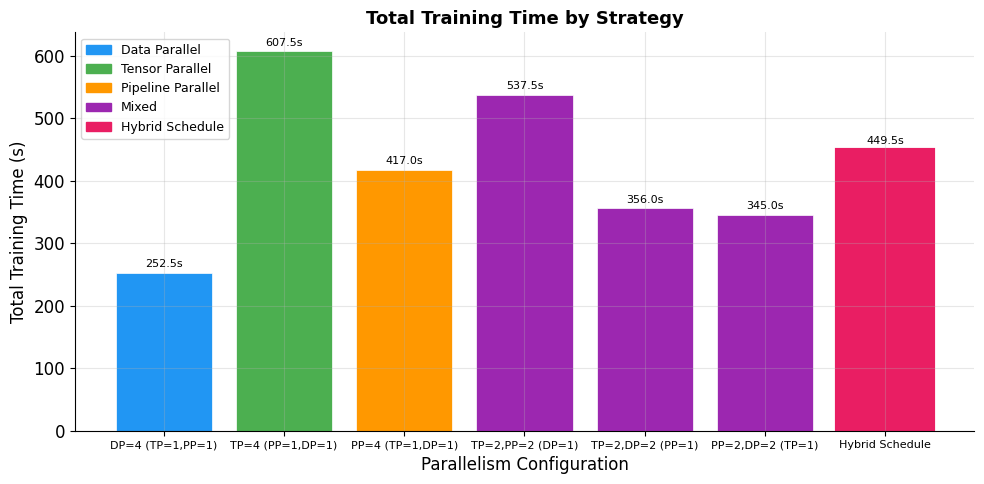

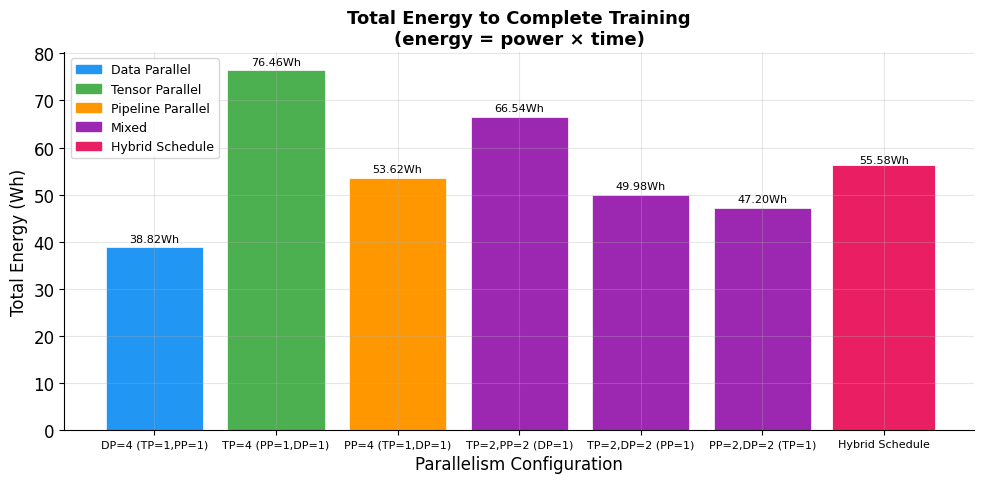

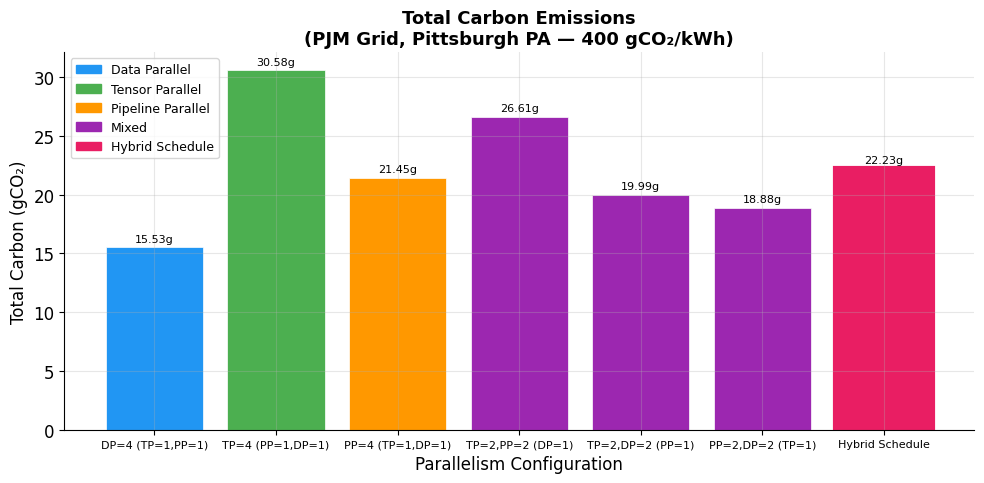

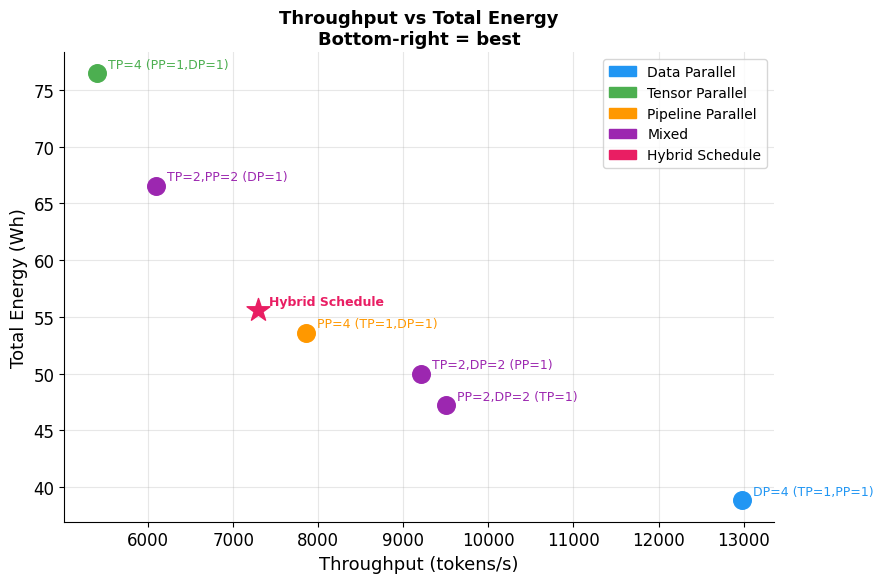

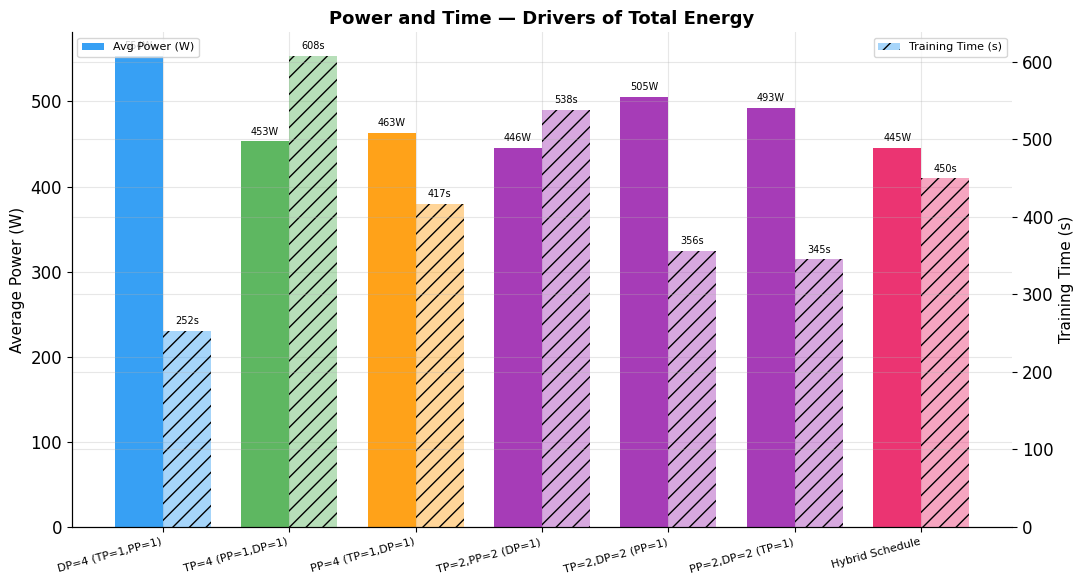

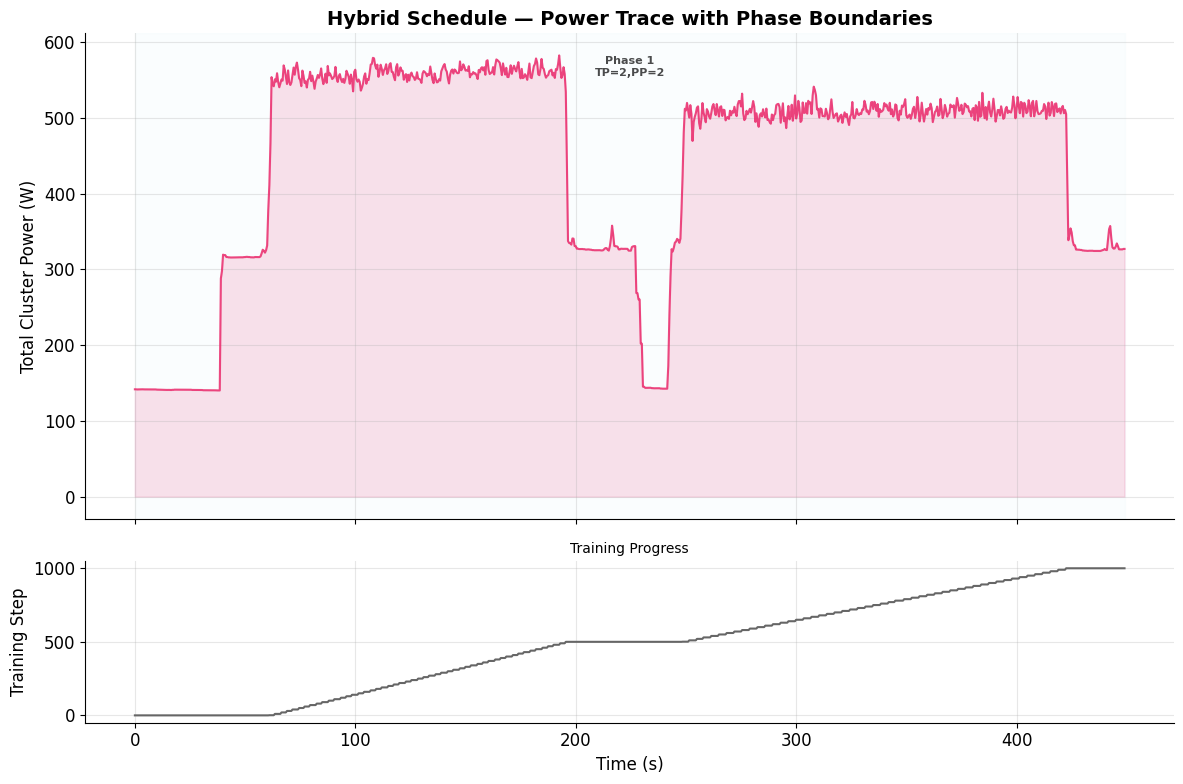

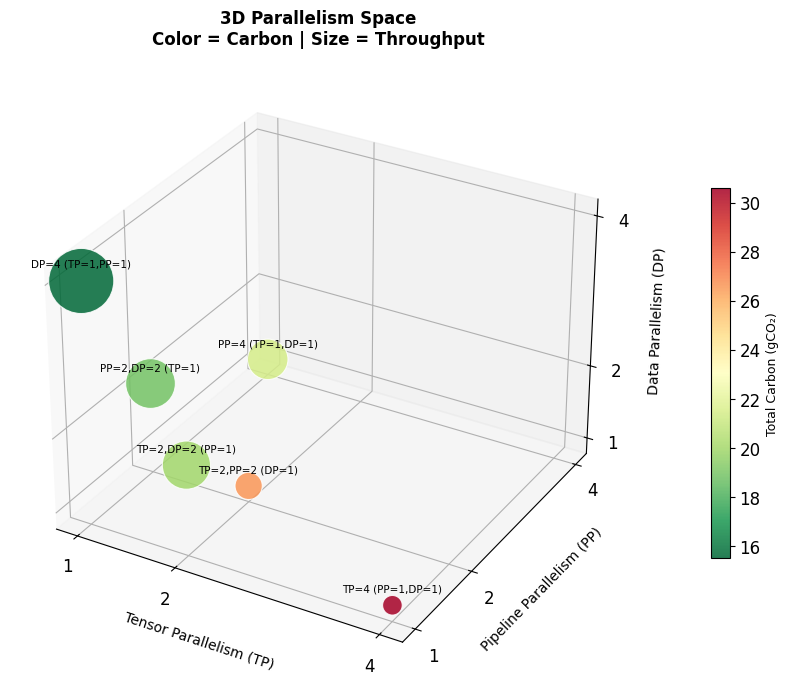


SUMMARY TABLE
          Config     Type  Time(s)  Avg Power(W)  Total Energy(Wh)  Total Carbon(gCO₂)  Throughput(tok/s)
DP=4 (TP=1,PP=1)   Static    252.5         553.5             38.82               15.53            12977.4
TP=4 (PP=1,DP=1)   Static    607.5         453.1             76.46               30.58             5393.9
PP=4 (TP=1,DP=1)   Static    417.0         462.9             53.62               21.45             7858.0
TP=2,PP=2 (DP=1)   Static    537.5         445.6             66.54               26.61             6096.4
TP=2,DP=2 (PP=1)   Static    356.0         505.4             49.98               19.99             9204.5
PP=2,DP=2 (TP=1)   Static    345.0         492.5             47.20               18.88             9498.0
 Hybrid Schedule Schedule    449.5         445.1             55.58               22.23             7289.9

Saved to: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/plots/gpt2/summary_table.csv


In [2]:
# Visualization Notebook
#
# Analyzes power logs from 3D parallelism benchmarks.
# Includes both static configs AND the hybrid/schedule strategy.
#
# Key insight: for a fixed training job, what matters is TOTAL energy
# and carbon (energy = power × time), not per-token rates.

# =====================================================================
# 1) Imports and Plot Style
# =====================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.cm as cm

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

COLORS = {
    "dp": "#2196F3",
    "tp": "#4CAF50",
    "pp": "#FF9800",
    "mixed": "#9C27B0",
    "schedule": "#E91E63",
}
PLOTS_DIR = os.path.join(os.getcwd(), "plots")
os.makedirs(PLOTS_DIR, exist_ok=True)

# =====================================================================
# 2) Load CSVs and Compute Power Statistics
# =====================================================================
BASE = os.getcwd()
MODEL_NAME = "gpt2"
DATA_DIR = os.path.join(BASE, "power_logs", MODEL_NAME)
PLOTS_DIR = os.path.join(BASE, "plots", MODEL_NAME)
os.makedirs(PLOTS_DIR, exist_ok=True)
print(f"Reading power logs from: {DATA_DIR}")
print(f"Saving plots to: {PLOTS_DIR}")

# ── Static configs ───────────────────────────────────────────
all_possible_configs = {
    "tp1_pp1_dp4": {"tp": 1, "pp": 1, "dp": 4, "file": "tp1_pp1_dp4_power.csv", "is_schedule": False},
    "tp4_pp1_dp1": {"tp": 4, "pp": 1, "dp": 1, "file": "tp4_pp1_dp1_power.csv", "is_schedule": False},
    "tp1_pp4_dp1": {"tp": 1, "pp": 4, "dp": 1, "file": "tp1_pp4_dp1_power.csv", "is_schedule": False},
    "tp2_pp2_dp1": {"tp": 2, "pp": 2, "dp": 1, "file": "tp2_pp2_dp1_power.csv", "is_schedule": False},
    "tp2_pp1_dp2": {"tp": 2, "pp": 1, "dp": 2, "file": "tp2_pp1_dp2_power.csv", "is_schedule": False},
    "tp1_pp2_dp2": {"tp": 1, "pp": 2, "dp": 2, "file": "tp1_pp2_dp2_power.csv", "is_schedule": False},
}

# ── Schedule/hybrid config ───────────────────────────────────
schedule_configs = {
    "hybrid_schedule": {
        "tp": None, "pp": None, "dp": None,
        "file": "schedule_example_schedule_power.csv",
        "is_schedule": True,
    },
}

def load_power_csv(path):
    """Load a power CSV with the standard format:
    timestamp, time_step, total_power_W, GPU_0_W, GPU_1_W, GPU_2_W, GPU_3_W
    """
    df = pd.read_csv(path)
    # Normalize column names
    df.columns = [c.strip() for c in df.columns]
    # Ensure we have the expected columns
    if "time_step" not in df.columns:
        # Old format without time_step
        df.columns = ["timestamp", "total_power_W",
                       "GPU_0_W", "GPU_1_W", "GPU_2_W", "GPU_3_W"]
        df["time_step"] = 0
    return df


# Load all configs
configs = {}
skipped = []

for name, cfg in {**all_possible_configs, **schedule_configs}.items():
    path = os.path.join(DATA_DIR, cfg["file"])
    if not os.path.exists(path):
        skipped.append(name)
        continue
    df = load_power_csv(path)
    if len(df) < 2:
        skipped.append(name)
        continue

    warmup = int(len(df) * 0.2)
    steady = df.iloc[warmup:]

    cfg["avg_power"] = df["total_power_W"].mean()
    cfg["steady_avg_power"] = steady["total_power_W"].mean()
    cfg["peak_power"] = df["total_power_W"].max()
    cfg["df"] = df
    configs[name] = cfg

    sched_tag = " [SCHEDULE]" if cfg["is_schedule"] else ""
    print(
        f"{name}{sched_tag}: avg={cfg['avg_power']:.1f}W  "
        f"steady_avg={cfg['steady_avg_power']:.1f}W  "
        f"peak={cfg['peak_power']:.1f}W  samples={len(df)}"
    )

if skipped:
    print(f"\nSkipped (missing or empty): {', '.join(skipped)}")

# Split into static and schedule
static_configs = {k: v for k, v in configs.items() if not v["is_schedule"]}
sched_configs = {k: v for k, v in configs.items() if v["is_schedule"]}

# =====================================================================
# 2b) Power traces per config (including schedule)
# =====================================================================
n_configs = len(configs)
if n_configs > 0:
    ncols = min(3, n_configs)
    nrows = (n_configs + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows),
                             sharex=False, sharey=False)
    axes = np.atleast_1d(axes).flatten()

    for ax, (name, cfg) in zip(axes, configs.items()):
        df = cfg["df"].copy()
        warmup_idx = int(len(df) * 0.2)

        x = np.arange(len(df)) * 0.5
        y = df["total_power_W"].to_numpy()

        ax.plot(x[:warmup_idx], y[:warmup_idx], color="#B0BEC5",
                linewidth=1.8, label="Warmup (first 20%)")
        ax.plot(x[warmup_idx:], y[warmup_idx:],
                color=COLORS["schedule"] if cfg["is_schedule"] else "#1976D2",
                linewidth=2.0, label="Steady-state")

        ax.axvline(x[warmup_idx] if warmup_idx < len(x) else x[-1],
                   color="#E53935", linestyle="--", linewidth=1.2)
        ax.axhline(cfg["steady_avg_power"], color="#43A047",
                   linestyle=":", linewidth=1.5)

        if cfg["is_schedule"]:
            title = "Hybrid Schedule"
            # Mark phase boundaries using time_step changes
            steps = df["time_step"].to_numpy()
            # Find where step resets to a lower value (phase boundary)
            for j in range(1, len(steps)):
                if steps[j] < steps[j-1] and steps[j-1] > 0:
                    ax.axvline(x[j], color="#FF9800", linestyle="-.",
                               linewidth=1, alpha=0.7)
        else:
            title = f"TP={cfg['tp']}, PP={cfg['pp']}, DP={cfg['dp']}"

        ax.set_title(title, fontsize=10, fontweight="bold")
        ax.set_xlabel("Time (s)", fontsize=9)
        ax.set_ylabel("Total Power (W)", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.text(0.02, 0.92, f"steady avg={cfg['steady_avg_power']:.1f}W",
                transform=ax.transAxes, fontsize=8, color="#2E7D32")

    for ax in axes[n_configs:]:
        ax.set_visible(False)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper left", ncol=4,
               fontsize=9, frameon=False)
    fig.suptitle("Power Consumption Per Configuration",
                 fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph0_power_trends.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 2c) Cumulative carbon over time (all configs + schedule)
# =====================================================================
INTERVAL_SECONDS = 0.5
CARBON_INTENSITY_G_PER_KWH_LOCAL = 400

if n_configs > 0:
    fig, ax = plt.subplots(figsize=(11, 6))

    for name, cfg in configs.items():
        df = cfg["df"].copy()
        x = np.arange(len(df)) * INTERVAL_SECONDS

        grams_per_sample = (
            df["total_power_W"].to_numpy() * INTERVAL_SECONDS / 3_600_000
        ) * CARBON_INTENSITY_G_PER_KWH_LOCAL
        cumulative_grams = np.cumsum(grams_per_sample)

        style = {"linewidth": 3.0, "linestyle": "--"} if cfg["is_schedule"] else {"linewidth": 2.0}
        label = "Hybrid Schedule" if cfg["is_schedule"] else \
                f"TP={cfg['tp']}, PP={cfg['pp']}, DP={cfg['dp']}"
        color = COLORS["schedule"] if cfg["is_schedule"] else None

        ax.plot(x, cumulative_grams, label=label, color=color, **style)
        ax.scatter(x[-1], cumulative_grams[-1], s=45, zorder=3,
                   color=color)

    ax.set_xlabel("Time (s)", fontsize=12)
    ax.set_ylabel("Cumulative Carbon Emissions (gCO₂)", fontsize=12)
    ax.set_title("Cumulative Carbon Emissions\nEndpoint = total job carbon",
                 fontsize=14, fontweight="bold")
    ax.legend(fontsize=8, ncol=2, frameon=False)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph0_carbon_trends.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 2d) Time-Varying Carbon Intensity Analysis
#
# A = [c_1, c_2, ..., c_t] splits training into t equal periods
# where period i has carbon intensity c_i (gCO2/kWh).
# =====================================================================
A = [200, 600]  # first half low carbon, second half high carbon
CI_FIXED = 400  # baseline constant

def get_ci_schedule(n_samples, A):
    """Return per-sample carbon intensity array from schedule A."""
    ci = np.zeros(n_samples)
    period_len = n_samples / len(A)
    for i, c in enumerate(A):
        start = int(i * period_len)
        end = int((i + 1) * period_len) if i < len(A) - 1 else n_samples
        ci[start:end] = c
    return ci

def compute_carbon(power_samples, ci_array, interval=0.5):
    """Compute cumulative and total carbon given per-sample CI."""
    energy_kwh = power_samples * interval / 3_600_000
    grams = energy_kwh * ci_array
    return np.cumsum(grams), grams.sum()

# Compute for all configs
print("\n" + "=" * 80)
print(f"CARBON SCHEDULE: A = {A} gCO₂/kWh")
print(f"Fixed baseline:  {CI_FIXED} gCO₂/kWh")
print("=" * 80)

print(f"\n{'Config':25s} | {'Fixed CI':>10s} | {'Varying CI':>10s} | {'Δ':>8s}")
print("-" * 60)

for name, cfg in configs.items():
    power = cfg["df"]["total_power_W"].to_numpy()
    n = len(power)
    ci_fixed = np.full(n, CI_FIXED)
    ci_varying = get_ci_schedule(n, A)

    _, fixed_total = compute_carbon(power, ci_fixed)
    _, varying_total = compute_carbon(power, ci_varying)
    delta_pct = (varying_total - fixed_total) / fixed_total * 100

    cfg["carbon_fixed_g"] = fixed_total
    cfg["carbon_varying_g"] = varying_total

    label = "Hybrid Schedule" if cfg["is_schedule"] else \
            f"TP={cfg['tp']},PP={cfg['pp']},DP={cfg['dp']}"
    print(f"{label:25s} | {fixed_total:8.2f} g | {varying_total:8.2f} g | {delta_pct:+6.1f}%")

# ── Plot: cumulative carbon under both CI regimes ────────────
if n_configs > 0:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    for ax_idx, (ax, title_ci, use_varying) in enumerate(zip(
        axes,
        [f"Fixed CI ({CI_FIXED} gCO₂/kWh)", f"Varying CI (A={A})"],
        [False, True],
    )):
        for name, cfg in configs.items():
            power = cfg["df"]["total_power_W"].to_numpy()
            n = len(power)
            ci = get_ci_schedule(n, A) if use_varying else np.full(n, CI_FIXED)
            cum, _ = compute_carbon(power, ci)
            x = np.arange(n) * INTERVAL_SECONDS

            style = {"linewidth": 3.0, "linestyle": "--"} if cfg["is_schedule"] else {"linewidth": 2.0}
            label = "Hybrid Schedule" if cfg["is_schedule"] else \
                    f"TP={cfg['tp']},PP={cfg['pp']},DP={cfg['dp']}"
            color = COLORS["schedule"] if cfg["is_schedule"] else None

            ax.plot(x, cum, label=label, color=color, **style)
            ax.scatter(x[-1], cum[-1], s=45, zorder=3, color=color)

        # Shade CI periods on the varying plot
        if use_varying:
            x_max = max(len(cfg["df"]) for cfg in configs.values()) * INTERVAL_SECONDS
            period_len = x_max / len(A)
            ci_colors = ["#4CAF50", "#F44336", "#2196F3", "#FF9800", "#9C27B0"]
            for i, c in enumerate(A):
                ax.axvspan(i * period_len, (i + 1) * period_len,
                           alpha=0.08, color=ci_colors[i % len(ci_colors)])
                ax.text((i + 0.5) * period_len, ax.get_ylim()[0],
                        f"{c} g/kWh", ha="center", va="bottom",
                        fontsize=9, fontweight="bold", alpha=0.5)

        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Cumulative CO₂ (g)")
        ax.set_title(title_ci, fontsize=12, fontweight="bold")
        ax.legend(fontsize=7, ncol=2, frameon=False)

    plt.suptitle("Impact of Time-Varying Carbon Intensity",
                 fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph_carbon_varying_ci.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

# ── Bar chart: fixed vs varying ──────────────────────────────
if n_configs > 0:
    labels_ci = []
    fixed_vals = []
    varying_vals = []
    bar_colors = []

    for name, cfg in configs.items():
        labels_ci.append("Hybrid\nSchedule" if cfg["is_schedule"] else
                         f"TP={cfg.get('tp','?')}\nPP={cfg.get('pp','?')}\nDP={cfg.get('dp','?')}")
        fixed_vals.append(cfg["carbon_fixed_g"])
        varying_vals.append(cfg["carbon_varying_g"])
        bar_colors.append(COLORS["schedule"] if cfg["is_schedule"] else "#546E7A")

    x = np.arange(len(labels_ci))
    width = 0.35

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(x - width/2, fixed_vals, width, color=bar_colors,
           alpha=0.5, label=f"Fixed CI ({CI_FIXED} g/kWh)")
    ax.bar(x + width/2, varying_vals, width, color=bar_colors,
           edgecolor="black", linewidth=0.5,
           label=f"Varying CI (A={A})")

    ax.set_ylabel("Total Carbon (gCO₂)", fontsize=12)
    ax.set_title(f"Fixed vs Time-Varying Carbon Intensity (A={A})",
                 fontsize=13, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(labels_ci, fontsize=8)
    ax.legend(fontsize=10)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph_carbon_fixed_vs_varying.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

# ── Theoretical optimal ─────────────────────────────────────
static_only = {k: v for k, v in configs.items() if not v["is_schedule"]}
if static_only:
    fastest = max(static_only.items(), key=lambda kv: kv[1].get("tokens_per_sec", 0))
    lowest_power = min(static_only.items(), key=lambda kv: kv[1]["steady_avg_power"])
    print(f"\nOptimal carbon-aware schedule for A={A}:")
    print(f"  Period 1 (CI={A[0]}) → {fastest[0]} (fast, power ok since CI is low)")
    print(f"  Period 2 (CI={A[1]}) → {lowest_power[0]} (low power since CI is high)")

# =====================================================================
# 3) Shared Constants
# =====================================================================
CARBON_INTENSITY_G_PER_KWH = CI_FIXED
TRAIN_ITERS = 200
GLOBAL_BATCH = 16
SEQ_LEN = 1024
INTERVAL = 0.5

def _classify(cfg):
    if cfg["is_schedule"]:
        return "schedule"
    dims_gt1 = sum(1 for d in (cfg["tp"], cfg["pp"], cfg["dp"]) if d > 1)
    if dims_gt1 >= 2:
        return "mixed"
    if cfg["tp"] > 1:
        return "tp"
    if cfg["pp"] > 1:
        return "pp"
    return "dp"

def _label(cfg):
    if cfg["is_schedule"]:
        return "Hybrid\nSchedule"
    parts = []
    if cfg["tp"] > 1: parts.append(f"TP={cfg['tp']}")
    if cfg["pp"] > 1: parts.append(f"PP={cfg['pp']}")
    if cfg["dp"] > 1: parts.append(f"DP={cfg['dp']}")
    main = ",".join(parts) if parts else "DP=1"
    others = []
    if cfg["tp"] == 1 and any(c > 1 for c in (cfg["pp"], cfg["dp"])):
        others.append("TP=1")
    if cfg["pp"] == 1 and any(c > 1 for c in (cfg["tp"], cfg["dp"])):
        others.append("PP=1")
    if cfg["dp"] == 1 and any(c > 1 for c in (cfg["tp"], cfg["pp"])):
        others.append("DP=1")
    return f"{main}\n({','.join(others)})" if others else main

all_configs = []
for name, cfg in configs.items():
    ctype = _classify(cfg)
    label = _label(cfg)
    all_configs.append((label, ctype, cfg))

# =====================================================================
# 4) Compute total energy/carbon/throughput metrics
# =====================================================================
total_tokens = TRAIN_ITERS * GLOBAL_BATCH * SEQ_LEN

print(f"\n{'Label':25s} | {'Time':>7s} | {'Power':>7s} | "
      f"{'Energy':>8s} | {'Carbon':>8s} | {'Tput':>10s}")
print("-" * 80)

for label, ctype, cfg in all_configs:
    power_samples = cfg["df"]["total_power_W"].to_numpy()
    total_time_s = len(power_samples) * INTERVAL
    total_energy_wh = power_samples.sum() * INTERVAL / 3600
    total_energy_kwh = total_energy_wh / 1000
    total_carbon_g = total_energy_kwh * CARBON_INTENSITY_G_PER_KWH
    avg_power_w = power_samples.mean()
    tokens_per_sec = total_tokens / total_time_s

    cfg["train_time_s"] = total_time_s
    cfg["total_time_s"] = total_time_s
    cfg["avg_power_w"] = avg_power_w
    cfg["total_energy_wh"] = total_energy_wh
    cfg["total_carbon_g"] = total_carbon_g
    cfg["tokens_per_sec"] = tokens_per_sec

    tag = " ★" if cfg["is_schedule"] else ""
    print(
        f"{label.replace(chr(10),' '):25s} | {total_time_s:6.1f}s | {avg_power_w:6.1f}W | "
        f"{total_energy_wh:7.2f}Wh | {total_carbon_g:6.2f}gCO₂ | "
        f"{tokens_per_sec:8.1f} tok/s{tag}"
    )

# =====================================================================
# 5) Graphs 1-3: Single-axis Power vs DP/TP/PP (static only)
# =====================================================================
def _plot_single_axis(dim_name, color_key, dim_key, graph_num):
    data = []
    for name, cfg in static_configs.items():
        data.append((cfg[dim_key], cfg["avg_power"], name))
    if len(data) < 2:
        return
    data.sort()
    xs, ys, _ = zip(*data)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot(xs, ys, "o-", color=COLORS[color_key], linewidth=2.5,
            markersize=10, markerfacecolor="white", markeredgewidth=2.5)
    for x, y in zip(xs, ys):
        ax.annotate(f"{y:.1f}W", (x, y), textcoords="offset points",
                    xytext=(8, 6), fontsize=10, color=COLORS[color_key])
    ax.set_xlabel(f"{dim_name} Parallelism Degree", fontsize=13)
    ax.set_ylabel("Total Cluster Power (W)", fontsize=13)
    ax.set_title(f"{dim_name} Parallelism vs Power", fontsize=14,
                 fontweight="bold")
    ax.set_xticks(sorted(set(xs)))
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, f"graph{graph_num}_{dim_key}_vs_power.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

_plot_single_axis("Data", "dp", "dp", 1)
_plot_single_axis("Tensor", "tp", "tp", 2)
_plot_single_axis("Pipeline", "pp", "pp", 3)

# =====================================================================
# 6) Graph 4: Power vs Total Training Time (all + schedule)
# =====================================================================
patches = [
    mpatches.Patch(color=COLORS["dp"], label="Data Parallel"),
    mpatches.Patch(color=COLORS["tp"], label="Tensor Parallel"),
    mpatches.Patch(color=COLORS["pp"], label="Pipeline Parallel"),
    mpatches.Patch(color=COLORS["mixed"], label="Mixed"),
    mpatches.Patch(color=COLORS["schedule"], label="Hybrid Schedule"),
]

if all_configs:
    fig, ax = plt.subplots(figsize=(9, 6))
    for label, ctype, cfg in all_configs:
        marker = "★" if cfg["is_schedule"] else "o"
        size = 250 if cfg["is_schedule"] else 150
        ax.scatter(cfg["train_time_s"], cfg["avg_power_w"],
                   color=COLORS[ctype], s=size, zorder=3,
                   marker=marker if not cfg["is_schedule"] else "*")
        ax.annotate(label.replace("\n", " "),
                    (cfg["train_time_s"], cfg["avg_power_w"]),
                    textcoords="offset points", xytext=(8, 4),
                    fontsize=9, color=COLORS[ctype],
                    fontweight="bold" if cfg["is_schedule"] else "normal")
    ax.legend(handles=patches, fontsize=10, loc="best")
    ax.set_xlabel("Total Training Time (s)", fontsize=13)
    ax.set_ylabel("Average Cluster Power (W)", fontsize=13)
    ax.set_title("Power vs Training Time\nTop-right = worst",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph4_power_vs_time.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 7) Graphs 5-9: Bar charts (all configs + schedule highlighted)
# =====================================================================
if all_configs:
    labels = [c[0].replace("\n", " ") for c in all_configs]
    colors = [COLORS[c[1]] for c in all_configs]
    time_vals = [c[2]["train_time_s"] for c in all_configs]
    energy_vals = [c[2]["total_energy_wh"] for c in all_configs]
    carbon_vals = [c[2]["total_carbon_g"] for c in all_configs]
    throughput_vals = [c[2]["tokens_per_sec"] for c in all_configs]
    is_sched = [c[2]["is_schedule"] for c in all_configs]

    # Edge colors: thick border for schedule
    edge_colors = ["#E91E63" if s else "white" for s in is_sched]
    edge_widths = [3 if s else 0.5 for s in is_sched]

    # Graph 5: Total training time
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(labels, time_vals, color=colors, edgecolor=edge_colors,
                  linewidth=edge_widths)
    for bar, val in zip(bars, time_vals):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max(time_vals) * 0.01,
                f"{val:.1f}s", ha="center", va="bottom", fontsize=8)
    ax.legend(handles=patches, fontsize=9)
    ax.set_ylabel("Total Training Time (s)", fontsize=12)
    ax.set_xlabel("Parallelism Configuration", fontsize=12)
    ax.set_title("Total Training Time by Strategy", fontsize=13,
                 fontweight="bold")
    ax.tick_params(axis="x", labelsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph5_total_time.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

    # Graph 6: Total energy
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(labels, energy_vals, color=colors, edgecolor=edge_colors,
                  linewidth=edge_widths)
    for bar, val in zip(bars, energy_vals):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max(energy_vals) * 0.01,
                f"{val:.2f}Wh", ha="center", va="bottom", fontsize=8)
    ax.legend(handles=patches, fontsize=9)
    ax.set_ylabel("Total Energy (Wh)", fontsize=12)
    ax.set_xlabel("Parallelism Configuration", fontsize=12)
    ax.set_title("Total Energy to Complete Training\n(energy = power × time)",
                 fontsize=13, fontweight="bold")
    ax.tick_params(axis="x", labelsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph6_total_energy.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

    # Graph 7: Total carbon
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(labels, carbon_vals, color=colors, edgecolor=edge_colors,
                  linewidth=edge_widths)
    for bar, val in zip(bars, carbon_vals):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max(carbon_vals) * 0.01,
                f"{val:.2f}g", ha="center", va="bottom", fontsize=8)
    ax.legend(handles=patches, fontsize=9)
    ax.set_ylabel("Total Carbon (gCO₂)", fontsize=12)
    ax.set_xlabel("Parallelism Configuration", fontsize=12)
    ax.set_title("Total Carbon Emissions\n(PJM Grid, Pittsburgh PA — 400 gCO₂/kWh)",
                 fontsize=13, fontweight="bold")
    ax.tick_params(axis="x", labelsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph7_total_carbon.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

    # Graph 8: Throughput vs total energy (Pareto)
    fig, ax = plt.subplots(figsize=(9, 6))
    for label, ctype, cfg in all_configs:
        marker = "*" if cfg["is_schedule"] else "o"
        size = 300 if cfg["is_schedule"] else 160
        ax.scatter(cfg["tokens_per_sec"], cfg["total_energy_wh"],
                   color=COLORS[ctype], s=size, zorder=3, marker=marker)
        ax.annotate(label.replace("\n", " "),
                    (cfg["tokens_per_sec"], cfg["total_energy_wh"]),
                    textcoords="offset points", xytext=(8, 4),
                    fontsize=9, color=COLORS[ctype],
                    fontweight="bold" if cfg["is_schedule"] else "normal")
    ax.legend(handles=patches, fontsize=10, loc="best")
    ax.set_xlabel("Throughput (tokens/s)", fontsize=13)
    ax.set_ylabel("Total Energy (Wh)", fontsize=13)
    ax.set_title("Throughput vs Total Energy\nBottom-right = best",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph8_throughput_vs_energy.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

    # Graph 9: Grouped power + time bars
    x = np.arange(len(labels))
    width = 0.38
    fig, ax1 = plt.subplots(figsize=(11, 6))
    power_vals = [c[2]["avg_power_w"] for c in all_configs]
    bars1 = ax1.bar(x - width / 2, power_vals, width,
                    color=colors, alpha=0.9, label="Avg Power (W)")
    ax1.set_ylabel("Average Power (W)", fontsize=11)
    ax1.set_xticks(x)
    ax1.set_xticklabels(labels, rotation=15, ha="right", fontsize=8)

    ax2 = ax1.twinx()
    bars2 = ax2.bar(x + width / 2, time_vals, width,
                    color=colors, alpha=0.4, hatch="//",
                    label="Training Time (s)")
    ax2.set_ylabel("Training Time (s)", fontsize=11)

    for bar, val in zip(bars1, power_vals):
        ax1.text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + max(power_vals) * 0.01,
                 f"{val:.0f}W", ha="center", va="bottom", fontsize=7)
    for bar, val in zip(bars2, time_vals):
        ax2.text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + max(time_vals) * 0.01,
                 f"{val:.0f}s", ha="center", va="bottom", fontsize=7)

    ax1.set_title("Power and Time — Drivers of Total Energy",
                  fontsize=13, fontweight="bold")
    ax1.legend(loc="upper left", fontsize=8)
    ax2.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph9_power_and_time.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 8) NEW: Schedule-specific power trace with phase annotations
# =====================================================================
for name, cfg in sched_configs.items():
    df = cfg["df"].copy()
    x = np.arange(len(df)) * INTERVAL_SECONDS
    y = df["total_power_W"].to_numpy()
    steps = df["time_step"].to_numpy()

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                                    gridspec_kw={"height_ratios": [3, 1]})

    # Top: power trace
    ax1.plot(x, y, color=COLORS["schedule"], linewidth=1.5, alpha=0.8)
    ax1.fill_between(x, y, alpha=0.15, color=COLORS["schedule"])
    ax1.set_ylabel("Total Cluster Power (W)", fontsize=12)
    ax1.set_title("Hybrid Schedule — Power Trace with Phase Boundaries",
                  fontsize=14, fontweight="bold")

    # Shade phases with different colors
    phase_colors = ["#E3F2FD", "#E8F5E9", "#FFF3E0", "#F3E5F5"]
    phase_labels = [
        "Phase 1\nTP=2,PP=2",
        "Phase 2\nTP=1,PP=1",
        "Phase 3\nTP=4,PP=1",
        "Phase 4\nTP=2,PP=1",
    ]

    # Detect phase boundaries from step resets or large gaps
    boundaries = [0]
    for j in range(1, len(steps)):
        # Phase boundary: step drops or idle gap (power < 200W after training)
        if (steps[j] < steps[j-1] and steps[j-1] > 0):
            boundaries.append(j)
    boundaries.append(len(df))

    for p_idx in range(min(len(boundaries) - 1, len(phase_colors))):
        start_idx = boundaries[p_idx]
        end_idx = boundaries[p_idx + 1] if p_idx + 1 < len(boundaries) else len(df)
        if start_idx < len(x) and end_idx <= len(x):
            ax1.axvspan(x[start_idx], x[min(end_idx - 1, len(x) - 1)],
                        alpha=0.15, color=phase_colors[p_idx % len(phase_colors)])
            mid_x = (x[start_idx] + x[min(end_idx - 1, len(x) - 1)]) / 2
            if p_idx < len(phase_labels):
                ax1.text(mid_x, ax1.get_ylim()[1] * 0.95,
                         phase_labels[p_idx],
                         ha="center", va="top", fontsize=8,
                         fontweight="bold", alpha=0.7)

    # Bottom: training step
    ax2.plot(x, steps, color="#666", linewidth=1.5)
    ax2.set_xlabel("Time (s)", fontsize=12)
    ax2.set_ylabel("Training Step", fontsize=12)
    ax2.set_title("Training Progress", fontsize=10)

    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph_schedule_detailed.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 9) 3D Parallelism Space (static configs only)
# =====================================================================
static_all = [(l, c, cfg) for l, c, cfg in all_configs if not cfg["is_schedule"]]

if len(static_all) >= 2:
    tp_vals = [c[2]["tp"] for c in static_all]
    pp_vals = [c[2]["pp"] for c in static_all]
    dp_vals = [c[2]["dp"] for c in static_all]
    carbon_vals_3d = [c[2]["total_carbon_g"] for c in static_all]
    toks_vals = [c[2]["tokens_per_sec"] for c in static_all]
    lbls = [c[0].replace("\n", " ") for c in static_all]

    c_min, c_max = min(carbon_vals_3d), max(carbon_vals_3d)
    t_min, t_max = min(toks_vals), max(toks_vals)
    sizes = [200 + 2000 * (t - t_min) / (t_max - t_min + 1e-9)
             for t in toks_vals]

    fig = plt.figure(figsize=(11, 8))
    ax = fig.add_subplot(111, projection="3d")

    sc = ax.scatter(tp_vals, pp_vals, dp_vals,
                    c=carbon_vals_3d, cmap=cm.RdYlGn_r,
                    s=sizes, alpha=0.85, edgecolors="white", linewidths=0.8,
                    vmin=c_min, vmax=c_max)

    for tp, pp, dp, lbl in zip(tp_vals, pp_vals, dp_vals, lbls):
        ax.text(tp, pp, dp + 0.15, lbl, fontsize=7.5, ha="center",
                va="bottom", color="black")

    ax.set_xlabel("Tensor Parallelism (TP)", fontsize=10, labelpad=8)
    ax.set_ylabel("Pipeline Parallelism (PP)", fontsize=10, labelpad=8)
    ax.set_zlabel("Data Parallelism (DP)", fontsize=10, labelpad=8)
    ax.set_xticks([1, 2, 4])
    ax.set_yticks([1, 2, 4])
    ax.set_zticks([1, 2, 4])
    ax.set_title("3D Parallelism Space\nColor = Carbon | Size = Throughput",
                 fontsize=12, fontweight="bold", pad=15)

    cbar = fig.colorbar(sc, ax=ax, pad=0.1, shrink=0.6)
    cbar.set_label("Total Carbon (gCO₂)", fontsize=9)

    plt.savefig(os.path.join(PLOTS_DIR, "graph10_3d_carbon.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 10) Summary Table
# =====================================================================
if all_configs:
    summary_rows = []
    for label, _, cfg in all_configs:
        summary_rows.append({
            "Config": label.replace("\n", " "),
            "Type": "Schedule" if cfg["is_schedule"] else "Static",
            "Time(s)": round(cfg["train_time_s"], 1),
            "Avg Power(W)": round(cfg["avg_power_w"], 1),
            "Total Energy(Wh)": round(cfg["total_energy_wh"], 2),
            "Total Carbon(gCO₂)": round(cfg["total_carbon_g"], 2),
            "Throughput(tok/s)": round(cfg["tokens_per_sec"], 1),
        })

    summary_df = pd.DataFrame(summary_rows)
    print("\n" + "=" * 80)
    print("SUMMARY TABLE")
    print("=" * 80)
    print(summary_df.to_string(index=False))
    print()

    summary_df.to_csv(os.path.join(PLOTS_DIR, "summary_table.csv"), index=False)
    print(f"Saved to: {os.path.join(PLOTS_DIR, 'summary_table.csv')}")